# Arc and Distance Calculations

## Imports

In [1]:
# Import standard data prep and eda libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import ipywidgets as widgets
from IPython.display import display
from shapely.ops import nearest_points
from shapely.geometry import LineString
import random
import os
import time
import requests


## Data Mapping for Eventual Distance Calculations

| Feature | Role | Source file | Status |
|---|---|---|---|
| Hatcheries | Supply | `trout_hatcheries.gpkg` | Processed data folder |
| Coop Nurseries | Supply | `coop_nurseries.geojson` | Raw Data |
| Class A Streams | Demand | `pa_class_a_trout_streams.gpkg` | Raw Data |
| Stocked sections (Nate) | Demand | `sections.parquet` + `pa_trout.gpkg` | Processed, from Nate's `sections-pull` pipeline; keyed on `section_id`; used for every distance table |
| Roads | Arc | Public OSRM routing server (`router.project-osrm.org`) | Queried once; road table saved to `data/processed/hatchery_to_section_road_distance.{parquet,csv}` |

**This notebook reads tables, it doesn't build them.** `scripts/06_road_distances.py` builds the road, straight-line and co-op distance tables. Run that script first (VS Code's ▶ "Run Python File"), then this notebook for the maps and validation.

The raw `pa_stocked_trout_streams.gpkg` (1,064 rows, keyed on `GlobalID`) is no longer used here, because its section list doesn't match Nate's. `01_data_prep` still reviews it.

Figures are saved to `outputs/figures/travel_arcs/` and report tables to `outputs/tables/travel_arcs/`.

## Goal: Matrix of distance from Hatchery/Coop to Stream, using roads as arc


In [2]:
CRS_M = 5070          # CONUS Albers, meters
N_NEAREST = 2         # nearest sections per co-op nursery (set in scripts/06_road_distances.py; used here for titles)
PAUSE_S = 1.5         # OSRM server policy: at most 1 request per second (route map below)

# Figures and report tables from this notebook are saved here
FIG_DIR = "../outputs/figures/travel_arcs"
TABLE_DIR = "../outputs/tables/travel_arcs"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

# Import all layers in the same projected CRS for mapping and distance calculations.
hatcheries = gpd.read_file("../data/processed/trout_hatcheries.gpkg").to_crs(CRS_M)
coop_nurseries = gpd.read_file("../data/raw/Coop_nurseries.geojson").to_crs(CRS_M)
class_a = gpd.read_file("../data/raw/pa_class_a_trout_streams.gpkg").to_crs(CRS_M)
pa_boundary = gpd.read_file("../data/raw/pa_boundary.gpkg").to_crs(CRS_M)

# Nate's stocked sections (sections-pull branch): 1,045 sections keyed on section_id = f"{RFP_WaterID}_{SecNum}".
# Every distance table uses these, so they all join to his pipeline on section_id.
# sections.parquet is committed on his branch. pa_trout.gpkg is gitignored: rebuild it with his
# scripts/01_download_pfbc_layers.py and scripts/02_build_sections.py.
sections = gpd.read_file("../data/processed/pa_trout.gpkg", layer="sections")[["section_id", "geometry"]].merge(
    pd.read_parquet("../data/processed/sections.parquet"), on="section_id", validate="one_to_one"
).to_crs(CRS_M)

### Plot Nodes

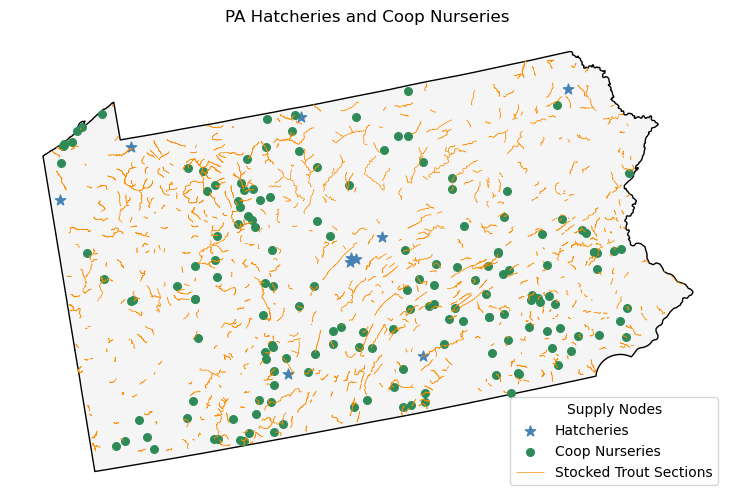

In [3]:
# Show hatcheries and coop nurseries on the map with distinct symbols.
fig, ax = plt.subplots(figsize=(10, 6))
pa_boundary.plot(ax=ax, color="whitesmoke", edgecolor="black")

hatcheries.plot(
    ax=ax,
    marker="*",
    color="steelblue",
    markersize=60,
    label="Hatcheries",
)
coop_nurseries.plot(
    ax=ax,
    marker="o",
    color="seagreen",
    markersize=30,
    label="Coop Nurseries",
)


sections.plot(
    ax=ax,
    color="darkorange",
    linewidth=0.5,
    label="Stocked Trout Sections",
)

ax.set_title("PA Hatcheries and Coop Nurseries")
ax.legend(title="Supply Nodes")
ax.set_axis_off()
fig.savefig(f"{FIG_DIR}/hatcheries_coops_stocked_sections.png", dpi=200, bbox_inches="tight")
plt.show()

## Calculate Distance from Supply Node to Demand Node, using Roads or Linear Distance as Arcs

### Coop Nurseries to Stocked Steams - Closest 2 streams

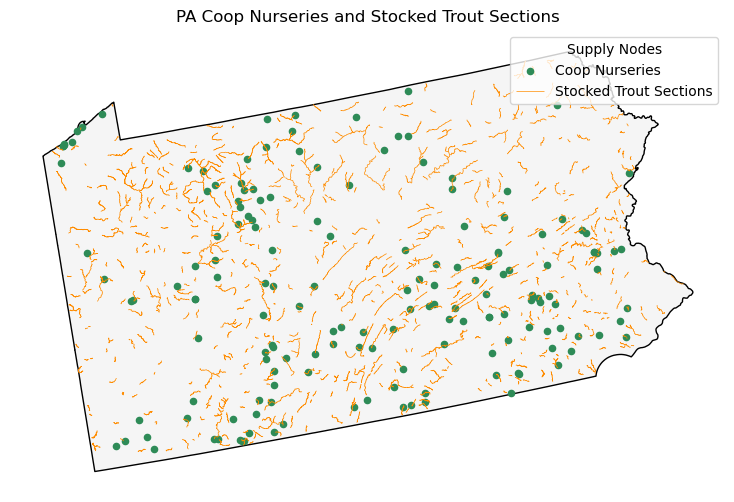

In [4]:
# Show coop nurseries against the stocked sections.
fig, ax = plt.subplots(figsize=(10, 6))
pa_boundary.plot(ax=ax, color="whitesmoke", edgecolor="black")

coop_nurseries.plot(
    ax=ax,
    marker="o",
    color="seagreen",
    markersize=20,
    label="Coop Nurseries",
)


sections.plot(
    ax=ax,
    color="darkorange",
    linewidth=0.5,
    label="Stocked Trout Sections",
)

ax.set_title("PA Coop Nurseries and Stocked Trout Sections")
ax.legend(title="Supply Nodes")
ax.set_axis_off()
fig.savefig(f"{FIG_DIR}/coops_stocked_sections.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
# The 2 nearest stocked sections to each co-op nursery (straight-line), built by scripts/06_road_distances.py
result = pd.read_csv("../data/interim/coop_nurseries_nearest_streams.csv")

In [6]:
result

,nursery_id,nursery,county,section_id,water_name,rank,dist_km
0,142,S.O.N.S,Erie,6072_2,Cascade Creek,1,1.32
1,142,S.O.N.S,Erie,3160_2,Elk Creek,2,15.69
2,203,PA Striped Bass,Huntingdon,3291_4,Great Trough Creek,1,7.74
3,203,PA Striped Bass,Huntingdon,2968_11,Raystown Branch Juniata River,2,8.30
4,212,Traditional Anglers of PA H/O Pond,Cambria,2076_2,Laurel Run,1,3.89
...,...,...,...,...,...,...,...
325,207,BMS Fisheries Program Nursery,Butler,314_3,Bonnie Brook,2,1.43
326,218,Shanksville School,Somerset,1326_2,Stonycreek River,1,0.59
327,218,Shanksville School,Somerset,30_2,Breastwork Run,2,7.50
328,23,Blairs Mills,Huntingdon,2890_2,Tuscarora Creek,1,0.03


### Review Nursey Linear Distance Results (Top 2 Matching)

Closest: Jim Thorpe — 0.0 km to nearest section


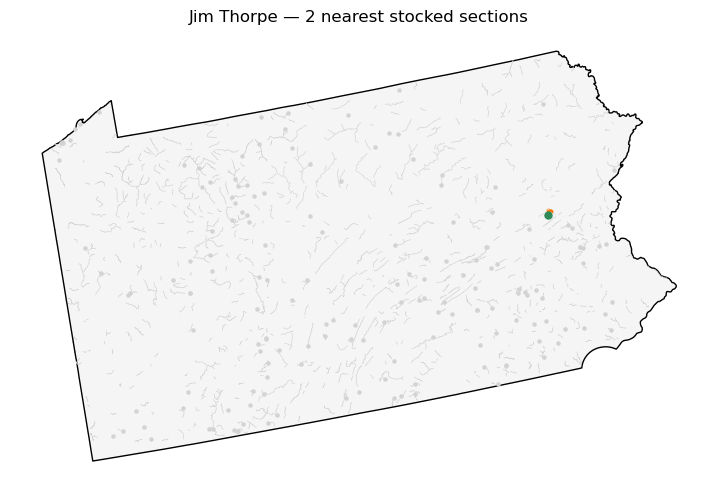

In [7]:

def plot_nursery(nursery_name, save=True):
    h = coop_nurseries.loc[
        coop_nurseries["NURSERY_NA"] == nursery_name
    ].iloc[0]
    near = result.loc[
        result["nursery"] == nursery_name
    ].sort_values("rank")

    fig, ax = plt.subplots(figsize=(9, 7))
    pa_boundary.plot(ax=ax, color="whitesmoke", edgecolor="black", zorder=0)
    sections.plot(ax=ax, color="lightgray", linewidth=0.4, zorder=1)
    coop_nurseries.plot(ax=ax, color="lightgray", markersize=5, zorder=2)
    coop_nurseries.loc[
        coop_nurseries["NURSERY_NA"] == nursery_name
    ].plot(ax=ax, color="seagreen", markersize=25, zorder=4)

    cmap = plt.cm.autumn_r
    for row in near.itertuples():
        section_geom = sections.loc[
            sections["section_id"] == row.section_id
        ]
        color = cmap(0.3 + 0.5 / row.rank)
        section_geom.plot(ax=ax, color=color, linewidth=2.5, zorder=3)
        nearest_on_section = nearest_points(
            h.geometry, section_geom.geometry.union_all()
        )[1]
        arc = LineString([h.geometry, nearest_on_section])
        gpd.GeoSeries([arc], crs=CRS_M).plot(
            ax=ax, color=color, linewidth=1.5, linestyle="--", zorder=3,
        )

    ax.set_title(f"{nursery_name} — {N_NEAREST} nearest stocked sections")
    ax.set_axis_off()
    if save:
        os.makedirs(f"{FIG_DIR}/coop_nursery_checks", exist_ok=True)
        slug = "".join(c if c.isalnum() else "_" for c in nursery_name).strip("_").lower()
        fig.savefig(f"{FIG_DIR}/coop_nursery_checks/{slug}.png", dpi=200, bbox_inches="tight")
    plt.show()


def plot_random_nursery():
    """Pick a random nursery and plot it."""
    name = random.choice(coop_nurseries["NURSERY_NA"].dropna().unique().tolist())
    plot_nursery(name)


def plot_by_section_id(section_id):
    """Plot whichever nursery has the given section_id among its nearest sections in `result`."""
    match = result.loc[result["section_id"] == section_id]
    if match.empty:
        raise ValueError(f"section_id {section_id!r} not found in result")
    plot_nursery(match.iloc[0]["nursery"])


def plot_farthest_nursery():
    """Plot the nursery whose closest section is farthest away."""
    row = result.loc[result["rank"] == 1].sort_values("dist_km", ascending=False).iloc[0]
    print(f"Farthest: {row['nursery']} — {row['dist_km']} km to nearest section")
    plot_nursery(row["nursery"])


def plot_closest_nursery():
    """Plot the nursery whose closest section is nearest of all."""
    row = result.loc[result["rank"] == 1].sort_values("dist_km", ascending=True).iloc[0]
    print(f"Closest: {row['nursery']} — {row['dist_km']} km to nearest section")
    plot_nursery(row["nursery"])


# --- run one of these (each saves its map to outputs/figures/travel_arcs/coop_nursery_checks/) ---
#plot_random_nursery()
# plot_by_section_id("3197_2")
#plot_nursery("3 C's Trout")
#plot_farthest_nursery()
plot_closest_nursery()

### Hatcheries Linear Distance Full Matrix

In [8]:
# Straight-line distance from every hatchery to every stocked section (nearest point on the section line),
# built by scripts/06_road_distances.py. The wide km matrix is in data/interim/hatchery_to_section_distance_matrix.csv.
hatchery_dist_long = pd.read_csv("../data/interim/hatchery_to_section_distance_long.csv")

print(f"rows: {len(hatchery_dist_long):,}")
hatchery_dist_long.head()

rows: 10,450


,hatchery_id,hatchery,county,section_id,water_name,dist_km,dist_mi
0,11,Reynoldsdale,Bedford,4502_2,Yellow Creek,59.474,36.955
1,11,Reynoldsdale,Bedford,2710_2,Riggles Gap Run,49.852,30.977
2,11,Reynoldsdale,Bedford,4502_4,Yellow Creek,63.979,39.755
3,11,Reynoldsdale,Bedford,202_2,Briar Creek,215.916,134.164
4,11,Reynoldsdale,Bedford,209_2,West Branch Briar Creek,213.651,132.757


### Sanity Check: Reynoldsdale distance to all stream sections (heat map)

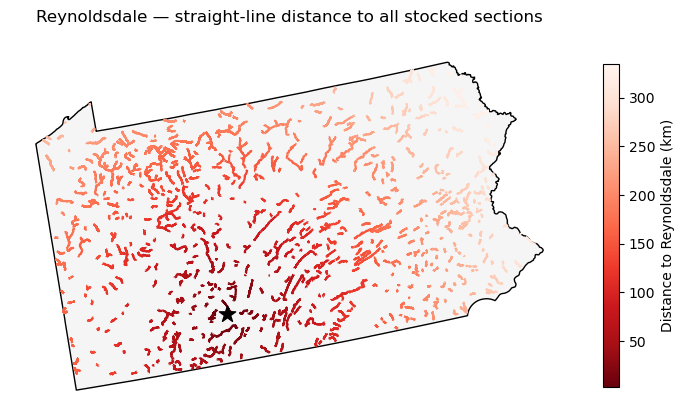

In [9]:
hatchery_name = "Reynoldsdale"

# Join each section's geometry to its distance from this hatchery
h_sections = sections.merge(
    hatchery_dist_long.loc[
        hatchery_dist_long["hatchery"] == hatchery_name,
        ["section_id", "dist_km"],
    ],
    on="section_id", how="inner",
)

fig, ax = plt.subplots(figsize=(9, 7))
pa_boundary.plot(ax=ax, color="whitesmoke", edgecolor="black", zorder=0)

# Reds_r: small dist_km (close) -> vibrant dark red, large dist_km (far) -> pale/light
h_sections.plot(
    ax=ax,
    column="dist_km",
    cmap="Reds_r",
    linewidth=1.5,
    zorder=2,
    legend=True,
    legend_kwds={"label": f"Distance to {hatchery_name} (km)", "shrink": 0.6},
)

hatcheries.loc[hatcheries["NAME"] == hatchery_name].plot(
    ax=ax, color="black", marker="*", markersize=150, zorder=3,
)

ax.set_title(f"{hatchery_name} — straight-line distance to all stocked sections")
ax.set_axis_off()
fig.savefig(f"{FIG_DIR}/{hatchery_name.lower()}_straight_line_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

### Hatcheries Matrix Network of Roads
Goal: Using Pennsylvania roads, find the shortest path from a hatchery to every stream section and compile into tabular format and eventually save as csv for usage in model later.

**Sections:** Nate's 1,045 stocked sections (`sections`), keyed on `section_id` so his pipeline can join this table directly. These are the 2024–26 stocked sections, 1,022 of them stocked in 2026.

**Approach** (in `scripts/06_road_distances.py`): the public [OSRM](https://project-osrm.org/) routing server's *table* service, which runs on an already-built OpenStreetMap road network. No local graph is built.
- Destinations are Nate's section midpoints (`mid_lon`/`mid_lat`). OSRM snaps every point to the nearest road and reports how far it moved (`snap_m`, and `hatchery_snap_m` for the start).
- The server allows non-commercial use at no more than 1 request per second, so requests are batched (100 sections each, 11 total) with a pause between them.

**Output:** `data/processed/hatchery_to_section_road_distance.parquet` plus a `.csv` copy, committed to git so Nate's pipeline can read it directly (Prompt 7). The script loads the saved parquet instead of calling the server again; set `REFRESH = True` in the script to re-query. The wide distance and drive-time matrices are in `data/interim`.

**Output columns** (one row per hatchery × section). ⚠️ `road_mi` and `road_min` look alike but measure different things:

| Column | Measures | Units | Notes |
|---|---|---|---|
| `road_km` | **Distance** along the route | kilometers | |
| `road_mi` | **Distance** along the route (same route as `road_km`) | **miles** | The cost input for the model (Nate's Prompt 7) |
| `road_min` | **Drive time** for that route | **minutes** | From OSRM's passenger-car speeds, so likely optimistic for a loaded stocking truck |
| `snap_m` | How far the section midpoint moved to reach a road | meters | Over 1,000 m means the distance is least reliable |
| `hatchery_snap_m` | How far the hatchery moved to reach a road | meters | |

OSRM picks the *fastest* route, and both distance and time describe that same route.

In [10]:
# Road table (model input), built by scripts/06_road_distances.py.
# road_km / road_mi = DISTANCE of the route; road_min = DRIVE TIME (minutes). See the column table above.
hatchery_road_dist_long = pd.read_parquet("../data/processed/hatchery_to_section_road_distance.parquet")

print(f"rows: {len(hatchery_road_dist_long):,}")
hatchery_road_dist_long.head()

rows: 10,450


,hatchery_id,hatchery,county,section_id,water_name,road_km,road_mi,road_min,snap_m,hatchery_snap_m
0,11,Reynoldsdale,Bedford,4502_2,Yellow Creek,89.459,55.587,82.6,24.0,99.9
1,11,Reynoldsdale,Bedford,2710_2,Riggles Gap Run,72.276,44.910,56.3,175.4,99.9
2,11,Reynoldsdale,Bedford,4502_4,Yellow Creek,78.538,48.801,87.3,210.7,99.9
3,11,Reynoldsdale,Bedford,202_2,Briar Creek,278.099,172.803,195.8,38.4,99.9
4,11,Reynoldsdale,Bedford,209_2,West Branch Briar Creek,279.155,173.459,196.1,46.4,99.9


In [11]:
# Per-hatchery summary of road distance to all sections (report table).
# "sections_closest_to" = how many sections have this hatchery as their nearest by road miles
# (the baseline assignment in Nate's model: each section is served by its nearest hatchery).
nearest = hatchery_road_dist_long.loc[hatchery_road_dist_long.groupby("section_id")["road_mi"].idxmin()]

hatchery_summary = (
    hatchery_road_dist_long.groupby(["hatchery_id", "hatchery", "county"])
    .agg(
        nearest_mi=("road_mi", "min"),
        median_mi=("road_mi", "median"),
        farthest_mi=("road_mi", "max"),
        median_drive_min=("road_min", "median"),
    )
    .round(1)
    .reset_index()
)
hatchery_summary["sections_closest_to"] = (
    hatchery_summary["hatchery"].map(nearest["hatchery"].value_counts()).fillna(0).astype(int)
)
hatchery_summary = hatchery_summary.sort_values("median_mi").reset_index(drop=True)
hatchery_summary.to_csv(f"{TABLE_DIR}/hatchery_road_distance_summary.csv", index=False)
hatchery_summary

,hatchery_id,hatchery,county,nearest_mi,median_mi,farthest_mi,median_drive_min,sections_closest_to
0,8,Benner Spring,Centre,12.6,114.9,215.1,160.3,50
1,7,Pleasant Gap,Centre,8.4,115.5,216.4,157.8,34
2,9,Bellefonte,Centre,9.0,116.9,231.5,158.4,3
3,10,Tylersville,Clinton,8.1,119.4,228.4,164.4,102
4,12,Huntsdale,Cumberland,5.0,136.8,319.6,185.8,223
5,11,Reynoldsdale,Bedford,6.7,141.8,282.5,185.4,179
6,5,Oswayo,Potter,4.8,160.3,294.5,249.2,85
7,4,Corry,Erie,10.0,192.4,381.0,269.6,133
8,6,Pleasant Mount,Wayne,9.0,192.7,375.3,258.1,159
9,2,Linesville,Crawford,12.5,207.0,405.6,267.1,77


In [12]:
# Validation summary for the road distance table.
# Each check states what's expected. Status: PASS, FAIL, or WARN (worth a look, not necessarily wrong).

n_expected = len(hatcheries) * len(sections)

# Straight-line distance from each hatchery to each section midpoint (the same points OSRM routes to)
mid_pts = gpd.GeoSeries(gpd.points_from_xy(sections["mid_lon"], sections["mid_lat"]), crs=4326).to_crs(CRS_M)
straight = pd.concat([
    pd.DataFrame({
        "hatchery_id": h.ID,
        "section_id": sections["section_id"].values,
        "straight_km": mid_pts.distance(h.geometry).values / 1000,
    })
    for h in hatcheries.itertuples()
], ignore_index=True)
check = hatchery_road_dist_long.merge(straight, on=["hatchery_id", "section_id"], how="left")

n_dupes = check.duplicated(["hatchery_id", "section_id"]).sum()
n_sections_covered = check["section_id"].nunique()
ids_2026 = set(sections.loc[sections["latest_year"] == 2026, "section_id"])
n_2026_covered = check.loc[check["section_id"].isin(ids_2026) & check["road_km"].notna(), "section_id"].nunique()
n_no_route = check["road_km"].isna().sum()
# Routes start and end at the snapped road points, so allow road to be short by up to both snap distances
n_shorter = (check["road_km"] < check["straight_km"] - (check["snap_m"] + check["hatchery_snap_m"]) / 1000).sum()
ratio = (check["road_km"] / check["straight_km"]).median()
speed_kmh = check["road_km"] / (check["road_min"] / 60)
snaps = check.drop_duplicates("section_id")[["section_id", "water_name", "snap_m"]]
far_snaps = snaps[snaps["snap_m"] > 1000]
far_hatcheries = check.drop_duplicates("hatchery")[["hatchery", "hatchery_snap_m"]].query("hatchery_snap_m > 1000")


def status(ok, warn_only=False):
    return "PASS" if ok else ("WARN" if warn_only else "FAIL")


checks = [
    ("Row count", f"{n_expected:,} (hatcheries x sections)", f"{len(check):,}",
     status(len(check) == n_expected)),
    ("Duplicate hatchery/section pairs", "0", n_dupes, status(n_dupes == 0)),
    ("Nate's sections covered", f"{len(sections):,}", f"{n_sections_covered:,}",
     status(n_sections_covered == len(sections))),
    ("Sections stocked in 2026 with a road distance", f"{len(ids_2026):,}", f"{n_2026_covered:,}",
     status(n_2026_covered == len(ids_2026))),
    ("Pairs with no road route", "0", n_no_route, status(n_no_route == 0)),
    ("Road shorter than straight-line (beyond snap)", "0", n_shorter, status(n_shorter == 0)),
    ("Median road / straight-line ratio", "1.1 to 1.6 (typical detour)", f"{ratio:.2f}",
     status(1.1 <= ratio <= 1.6)),
    ("Implied average speed (km/h)", "all between 20 and 120", f"{speed_kmh.min():.0f} to {speed_kmh.max():.0f}",
     status(speed_kmh.between(20, 120).all())),
    ("Hatcheries snapped > 1 km from a road", "0", len(far_hatcheries),
     status(len(far_hatcheries) == 0, warn_only=True)),
    ("Sections snapped > 1 km from a road", "0 (otherwise review list below)", len(far_snaps),
     status(len(far_snaps) == 0, warn_only=True)),
]
validation = pd.DataFrame(checks, columns=["check", "expected", "result", "status"])
validation.to_csv(f"{TABLE_DIR}/road_distance_validation.csv", index=False)
display(validation)

far_snaps_table = (
    far_snaps.merge(sections[["section_id", "county"]], on="section_id")
    .sort_values("snap_m", ascending=False)
    .reset_index(drop=True)
)
far_snaps_table.to_csv(f"{TABLE_DIR}/far_snapped_sections.csv", index=False)
if len(far_snaps_table):
    print("Sections snapped > 1 km: their midpoint is far from any road, so road distance is least reliable")
    display(far_snaps_table)

,check,expected,result,status
0,Row count,"10,450 (hatcheries x sections)","10,450",PASS
1,Duplicate hatchery/section pairs,0,0,PASS
2,Nate's sections covered,"1,045","1,045",PASS
3,Sections stocked in 2026 with a road distance,"1,022","1,022",PASS
4,Pairs with no road route,0,0,PASS
5,Road shorter than straight-line (beyond snap),0,0,PASS
6,Median road / straight-line ratio,1.1 to 1.6 (typical detour),1.34,PASS
7,Implied average speed (km/h),all between 20 and 120,30 to 87,PASS
8,Hatcheries snapped > 1 km from a road,0,0,PASS
9,Sections snapped > 1 km from a road,0 (otherwise review list below),7,WARN


Sections snapped > 1 km: their midpoint is far from any road, so road distance is least reliable


,section_id,water_name,snap_m,county
0,2973_2,Canoe Creek,2301.5,Blair
1,2906_3,Pithole Creek,1283.5,Venango
2,3301_2,Stony Creek,1158.5,Dauphin
3,2294_2,West Branch Dyberry Creek,1123.0,Wayne
4,1339_7,Pine Creek,1079.7,Tioga
5,6025_2,North Fork Redbank Creek,1049.5,Jefferson
6,1878_2,Bear Creek,1028.9,Elk


### Sanity Check: Reynoldsdale road routes (map)
The table service only returns numbers, so this pulls the actual road paths for a sample of sections, spread from nearest to farthest plus any snapped more than 1 km, using OSRM's *route* service. That takes one request per route, so it's a sample rather than all 1,045. Routes are cached to GeoPackage; delete the file to re-query.

loaded cached routes from ../data/interim/reynoldsdale_sample_routes.gpkg


routes: 29 | largest route-vs-table difference: 0.001 km


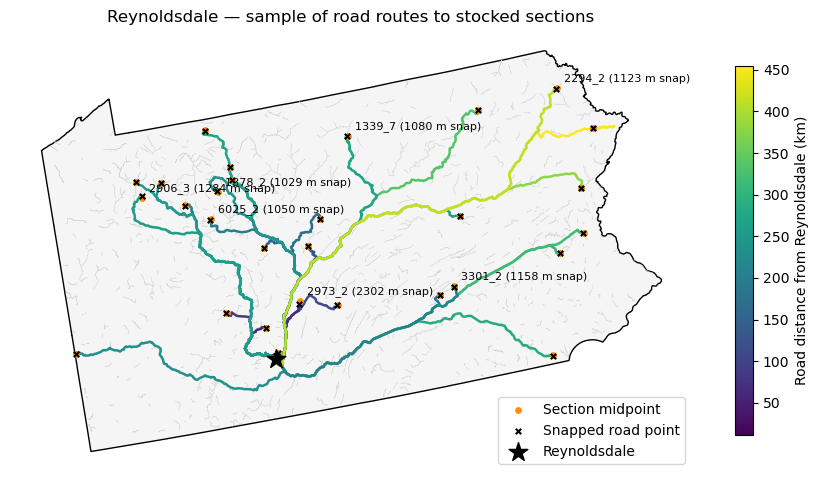

In [13]:
route_hatchery = "Reynoldsdale"
N_SAMPLE = 22   # evenly spaced from nearest to farthest; far-snapped sections are added on top
ROUTE_URL = "https://router.project-osrm.org/route/v1/driving/"
ROUTES_GPKG = f"../data/interim/{route_hatchery.lower().replace(' ', '_')}_sample_routes.gpkg"

h_row = hatcheries.loc[hatcheries["NAME"] == route_hatchery].iloc[0]
h_road = (
    hatchery_road_dist_long.loc[hatchery_road_dist_long["hatchery"] == route_hatchery]
    .sort_values("road_km")
    .reset_index(drop=True)
)
picks = h_road.iloc[np.linspace(0, len(h_road) - 1, N_SAMPLE).round().astype(int)]
picks = pd.concat([picks, h_road[h_road["snap_m"] > 1000]]).drop_duplicates("section_id")

if os.path.exists(ROUTES_GPKG):
    routes = gpd.read_file(ROUTES_GPKG)
    print(f"loaded cached routes from {ROUTES_GPKG}")
else:
    mids = sections.set_index("section_id")[["mid_lon", "mid_lat"]]
    recs = []
    for p in picks.itertuples():
        lon, lat = mids.loc[p.section_id]
        r = requests.get(
            f"{ROUTE_URL}{h_row['Long_']:.6f},{h_row['Lat']:.6f};{lon:.6f},{lat:.6f}",
            params={"overview": "full", "geometries": "geojson"},
            timeout=60,
        )
        r.raise_for_status()
        j = r.json()
        if j.get("code") != "Ok":
            raise RuntimeError(f"OSRM error: {j.get('code')} {j.get('message')}")
        snap_lon, snap_lat = j["waypoints"][1]["location"]
        recs.append({
            "section_id": p.section_id,
            "water_name": p.water_name,
            "table_km": p.road_km,
            "route_km": round(j["routes"][0]["distance"] / 1000, 3),
            "snap_m": p.snap_m,
            "mid_lon": lon, "mid_lat": lat,
            "snap_lon": snap_lon, "snap_lat": snap_lat,
            "geometry": LineString(j["routes"][0]["geometry"]["coordinates"]),
        })
        time.sleep(PAUSE_S)
    routes = gpd.GeoDataFrame(recs, crs=4326)
    routes.to_file(ROUTES_GPKG, driver="GPKG")

# Cross-check: the route service and the table service should agree on distance
diff_km = (routes["route_km"] - routes["table_km"]).abs()
print(f"routes: {len(routes)} | largest route-vs-table difference: {diff_km.max():.3f} km")

# Map
routes_m = routes.to_crs(CRS_M)
mid_pts_r = gpd.GeoSeries(gpd.points_from_xy(routes["mid_lon"], routes["mid_lat"]), crs=4326).to_crs(CRS_M)
snap_pts_r = gpd.GeoSeries(gpd.points_from_xy(routes["snap_lon"], routes["snap_lat"]), crs=4326).to_crs(CRS_M)
gaps = gpd.GeoSeries([LineString([a, b]) for a, b in zip(mid_pts_r, snap_pts_r)], crs=CRS_M)

fig, ax = plt.subplots(figsize=(11, 8))
pa_boundary.plot(ax=ax, color="whitesmoke", edgecolor="black", zorder=0)
sections.plot(ax=ax, color="lightgray", linewidth=0.4, zorder=1)
routes_m.plot(
    ax=ax, column="route_km", cmap="viridis", linewidth=1.8, zorder=2,
    legend=True, legend_kwds={"label": f"Road distance from {route_hatchery} (km)", "shrink": 0.6},
)
gaps.plot(ax=ax, color="red", linestyle=":", linewidth=1, zorder=3)
mid_pts_r.plot(ax=ax, color="darkorange", markersize=15, zorder=4, label="Section midpoint")
snap_pts_r.plot(ax=ax, color="black", marker="x", markersize=15, zorder=4, label="Snapped road point")
hatcheries.loc[hatcheries["NAME"] == route_hatchery].plot(
    ax=ax, color="black", marker="*", markersize=200, zorder=5, label=route_hatchery,
)

# Label the far-snapped sections so they can be found on the map
far = (routes["snap_m"] > 1000).values
for rec, pt in zip(routes.loc[far].itertuples(), mid_pts_r[far]):
    ax.annotate(f"{rec.section_id} ({rec.snap_m:.0f} m snap)", xy=(pt.x, pt.y),
                xytext=(5, 5), textcoords="offset points", fontsize=8)

ax.set_title(f"{route_hatchery} — sample of road routes to stocked sections")
ax.legend(loc="lower right")
ax.set_axis_off()
fig.savefig(f"{FIG_DIR}/{route_hatchery.lower()}_road_routes_sample.png", dpi=200, bbox_inches="tight")
plt.show()